# 03 GMM with time-ordered grid search

**Objective:** Fit Gaussian mixture models to daily stock observations to identify groups with similar patterns in returns, momentum, volatility and trading activity. We compare models with different number of groups and use chronological validation to choose a suitable number. There are no predefined "correct" group labels to compare against. 

GMM describes the data as a combination of several Gaussian, or bell-shaped, distributions. Each distribution is called a component and represents a possible group of observations. Components can overlap, so the model assigns each observation a probability of belonging to each group.

This is a simplified representation of real financial data. Returns can have heavy tails and are not necessarily normally distributed. Combining several Gaussian components can approximate a more complex distribution, but the groups still need to be examined to understand what they represent.


`n_components` sets how many groups the GMM tries to identify. `covariance_type` determines how the model describes variation within each group: `diag` estimates a separate variance for each feature within each component; `full` also models correlations but requires more parameters. `reg_covar=1e-5` stabilizes the covariance matrices, `n_init` reduces sensitivity to initialization, and `max_iter` limits the number of fitting iterations.

We use a simple loop to try different GMM settings, such as the number of components and the covariance type. Each combination is evaluated using the same walk-forward splits: train on 2017 and validate on 2018, train on 2017-2018 and validate on 2019, then train on 2017-2019 and validate on 2020. Training always uses earlier observations, and all stocks observed on one date remain together. The imputer and scaler are fitted only on the training rows within each fold. 

Because we do not know the correct cluster labels, we cannot evaluate the model using classification accuracy. Instead, we use mean validation log-likelihood to assess how well each GMM describes later, unseen observations. Higher values indicate better predictive density fit. We compare scores only within the same feature set and supplement them with checks of convergence, cluster stability, size, and interpretability.

GridSearchCV could perform this search if we supplied suitable date-based splits and scoring settings. We use an explicit loop to make the training periods, preprocessing steps and evaluation process easier to inspect.
Prepared observations come from `data/processed/`, and frozen feature lists come from `output/02_time_split_and_preprocessing/`. Save search reports and models under `output/03_gmm_grid_search/`. No Pickle dataset is needed.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src/config.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src/config.py").exists():
    raise FileNotFoundError("Open this notebook from the project root or notebooks folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

%load_ext autoreload
%autoreload 2

from src.config import ProjectConfig, options
from src.io_utils import (prepare_run, read_json, write_json, require_files,
                        ensure_unlocked, record_input_checksums, save_figure)
from src.data import balanced_sample,load_development_data, make_preprocessor, chronological_folds
from src.modeling import run_gmm_cv, summarize_cv, fit_candidates, shortlist_gmm_configurations

cfg = ProjectConfig()
RUN = prepare_run(ROOT, cfg)
ensure_unlocked(RUN)
record_input_checksums(ROOT, cfg, RUN)
FEATURES = ROOT / "output" / "02_time_split_and_preprocessing"
OUT = ROOT / "output" / "03_gmm_grid_search"
for folder in ("models", "tables", "figures"):
    (OUT / folder).mkdir(parents=True, exist_ok=True)
opt = options(cfg)
print(f"Experiment: {OUT.name} | Profile: {cfg.run_profile}\nNotebook results: {OUT}")


Experiment: 03_gmm_grid_search | Profile: full
Notebook results: C:\Users\MY NGOC\Documents\MAU_TACAS_68803\DA631E_ArtificialIntelligenceForDataScience\Project_2_UnsupervisedLearning\output\03_gmm_grid_search


In [2]:
require_files(FEATURES, ["feature_sets.json", "feature_filter_fit.json", "folds.csv"])
development_rows, data_audit = load_development_data(ROOT, cfg)
write_json(RUN / "data_audit.json", data_audit)
feature_sets = read_json(FEATURES / "feature_sets.json")
display(pd.DataFrame({
    "feature_set": feature_sets.keys(),
    "n_features": [len(features) for features in feature_sets.values()],
}))
print(f"Loaded {len(development_rows):,} development rows from {ROOT / cfg.development_features_path}")


,feature_set,n_features
0,A,42
1,B,35
2,C,16
3,D,8


Loaded 1,754,860 development rows from C:\Users\MY NGOC\Documents\MAU_TACAS_68803\DA631E_ArtificialIntelligenceForDataScience\Project_2_UnsupervisedLearning\data\processed\development_features.parquet


## Try one GMM first before grid search

In [3]:
train_rows = development_rows.loc[development_rows.Date <= pd.Timestamp(cfg.train_end)].copy()
train_rows.describe()

,Date,Close,Volume,OpenToCloseReturn,HighLowRange,GapReturn,LogReturn1Day,Momentum5Days,Momentum20Days,Momentum60Days,...,Fin_ResultDividendPerShareAnnual_SignedLog,Fin_ForecastDividendPerShareAnnual_SignedLog,Fin_ForecastNetSales_SignedLog,Fin_ForecastOperatingProfit_SignedLog,Fin_ForecastOrdinaryProfit_SignedLog,Fin_ForecastProfit_SignedLog,Fin_ForecastEarningsPerShare_SignedLog,FinancialAvailableDate,DayNumber,HistoryCount
count,1279342,1.279342e+06,1.279342e+06,1.279342e+06,1.279342e+06,1.279342e+06,1.279342e+06,1.279342e+06,1.279342e+06,1.279342e+06,...,1.201966e+06,1.239857e+06,1.238375e+06,1.206547e+06,1.247551e+06,1.258362e+06,1.251137e+06,1278967,1.279342e+06,1.279342e+06
mean,2018-08-17 12:55:07.310163712,2.572310e+03,7.036133e+05,3.486979e-05,2.418463e-02,4.220008e-04,2.083391e-04,2.219992e-03,8.450230e-03,2.408114e-02,...,3.201339e+00,3.294411e+00,2.523527e+01,2.182682e+01,2.183617e+01,2.127658e+01,4.491218e+00,2018-07-05 07:21:50.487292416,3.985886e+02,3.933612e+02
min,2017-03-31 00:00:00,1.900000e+01,1.000000e+02,-2.949513e-01,0.000000e+00,-3.502627e-01,-4.311871e-01,-7.762596e-01,-8.252981e-01,-8.328373e-01,...,0.000000e+00,0.000000e+00,1.909871e+01,-2.602158e+01,-2.663406e+01,-2.667130e+01,-6.993603e+00,2017-01-05 00:00:00,6.000000e+01,6.000000e+01
25%,2017-12-08 00:00:00,1.053000e+03,2.880000e+04,-8.678881e-03,1.364256e-02,-4.437870e-03,-9.646377e-03,-2.183406e-02,-4.498525e-02,-7.650748e-02,...,2.708050e+00,2.803360e+00,2.418900e+01,2.146520e+01,2.152302e+01,2.109483e+01,4.083452e+00,2017-11-02 00:00:00,2.310000e+02,2.250000e+02
50%,2018-08-16 00:00:00,1.851000e+03,1.073000e+05,0.000000e+00,1.980198e-02,0.000000e+00,0.000000e+00,1.297017e-03,4.701142e-03,5.571439e-03,...,3.367296e+00,3.433987e+00,2.518341e+01,2.239097e+01,2.242801e+01,2.203160e+01,4.706011e+00,2018-07-28 00:00:00,4.000000e+02,3.920000e+02
75%,2019-04-24 00:00:00,3.065000e+03,4.080000e+05,8.277192e-03,2.933333e-02,5.555556e-03,9.852296e-03,2.480620e-02,5.522682e-02,1.001410e-01,...,3.931826e+00,4.007333e+00,2.624473e+01,2.343198e+01,2.352663e+01,2.312116e+01,5.295363e+00,2019-02-28 00:00:00,5.670000e+02,5.610000e+02
max,2019-12-30 00:00:00,7.521000e+04,4.034704e+08,3.571429e-01,6.141732e-01,9.658537e-01,7.511860e-01,2.155702e+00,4.758621e+00,5.653386e+00,...,6.911857e+00,6.714171e+00,3.103222e+01,2.856711e+01,2.863165e+01,2.850649e+01,8.461680e+00,2019-12-28 00:00:00,7.320000e+02,7.320000e+02
std,NaN,3.281945e+03,3.979130e+06,1.770259e-02,1.759724e-02,1.362111e-02,2.170280e-02,4.972797e-02,9.981111e-02,1.774392e-01,...,1.156901e+00,1.128204e+00,1.624476e+00,5.743150e+00,5.960234e+00,6.482909e+00,1.529184e+00,NaN,1.943110e+02,1.943105e+02


In [4]:
from sklearn.mixture import GaussianMixture
_, early_train, early_valid = next(chronological_folds(train_rows, cfg))
a = balanced_sample(early_train, opt["train_cap"], cfg.random_seed)
b = balanced_sample(early_valid, opt["validation_cap"], cfg.random_seed)
columns = feature_sets["D"]
prep = make_preprocessor()
x = prep.fit_transform(a[columns])
z = prep.transform(b[columns])
one_gmm = GaussianMixture(n_components=2, covariance_type="diag", reg_covar=1e-5,
                        n_init=opt["n_init"], max_iter=opt["max_iter"], random_state=cfg.random_seed)
one_gmm.fit(x)
print("Coverged:", one_gmm.converged_)
print("LL on future observations:", one_gmm.score(z))
print("First 5 states:", one_gmm.predict(z[:5]))
print("First observation's probability:", one_gmm.predict_proba(z[:1]))

Coverged: True
LL on future observations: -11.369810832097514
First 5 states: [0 0 0 0 0]
First observation's probability: [[0.99821927 0.00178073]]


## Grid search: 
First screening with smaller variations of hyperparameters

In [5]:
cfg = ProjectConfig(
    run_profile="quick",
    run_name="03_gmm_quick_check",
)

opt = options(cfg)

In [6]:
first_validation_year = pd.Timestamp(cfg.feature_selection_end).year + 1
n_folds = pd.Timestamp(cfg.development_end).year - first_validation_year + 1

number_of_fits = (
    len(feature_sets)
    * n_folds                       
    * len(opt["k"])
    * len(opt["covariance"])
    * len(opt["random_seeds"])
)

print("Number of model fits:", number_of_fits)

print(f"Run profile: {cfg.run_profile}")
print("\nHyperparameter choices:")
print(f"  n_components:    {opt['k']}")
print(f"  covariance_type: {opt['covariance']}")
print(f"  random_state:    {opt['random_seeds']}")

print("\nFixed training settings:")
print(f"  n_init:          {opt['n_init']}")
print(f"  max_iter:        {opt['max_iter']}")
print(f"  reg_covar:       {1e-5}")
print(f"  Training rows:   {opt['train_cap'] or 'All'} per fold")
print(f"  Validation rows: {opt['validation_cap'] or 'All'} per fold")

Number of model fits: 120
Run profile: quick

Hyperparameter choices:
  n_components:    [2, 3, 4, 5, 6]
  covariance_type: ['diag', 'full']
  random_state:    [24]

Fixed training settings:
  n_init:          2
  max_iter:        200
  reg_covar:       1e-05
  Training rows:   50000 per fold
  Validation rows: 50000 per fold


In [7]:

cv = run_gmm_cv(development_rows, feature_sets, cfg)


Starting GMM CV: 120 fits across 3 folds and 4 feature sets.

validate_2018: 349,699 training rows, 464,576 validation rows.
  Actual rows used: 50,000 training, 50,000 validation
  Preparing feature set A (42 features)...
  [1/120] validate_2018, set A, k=2, covariance=diag, seed=24: done (elapsed 1.4s)
  [10/120] validate_2018, set A, k=6, covariance=full, seed=24: done (elapsed 37.1s)
  Preparing feature set B (35 features)...
  [20/120] validate_2018, set B, k=6, covariance=full, seed=24: done (elapsed 71.1s)
  Preparing feature set C (16 features)...
  [30/120] validate_2018, set C, k=6, covariance=full, seed=24: done (elapsed 87.4s)
  Preparing feature set D (8 features)...
  [40/120] validate_2018, set D, k=6, covariance=full, seed=24: done (elapsed 104.7s)

validate_2019: 814,275 training rows, 465,067 validation rows.
  Actual rows used: 50,000 training, 50,000 validation
  Preparing feature set A (42 features)...
  [50/120] validate_2019, set A, k=6, covariance=full, seed=24:

In [8]:
cv.to_csv(OUT / "gmm_cv.csv", index=False)
cv_summary = summarize_cv(cv)
cv_summary.to_csv(OUT / "gmm_cv_summ           ary.csv", index=False)
display(cv_summary)

,feature_set,k,covariance,mean_valid_ll,std_valid_ll,all_converged,n_runs,n_scored
9,A,6,full,14.800465,6.091921,True,3,3
7,A,5,full,11.024320,6.248991,True,3,3
5,A,4,full,10.989122,7.377263,True,3,3
3,A,3,full,7.650965,10.521610,True,3,3
1,A,2,full,-2.568365,13.394733,True,3,3
8,A,6,diag,-16.267851,4.772954,True,3,3
6,A,5,diag,-18.097105,5.916259,True,3,3
4,A,4,diag,-20.855744,4.258458,True,3,3
2,A,3,diag,-26.508776,5.429965,True,3,3
0,A,2,diag,-37.152284,6.542545,True,3,3


## What do we optimize?
`model.score(X_valid)` is average log-likelihood for later and unseen observations. For every feature set, the combination of component number and covariance type are chosen to have the highest average value over all folds, also combinations where all runs converged.

Compare only these LL-value within same feature set. It is not correct to choose A instead of D because A's density or BIC has a specific numerical value. The training BIC is saved as supplementary information for the same feature matrix; the selection here is based on time-based validation.

The standard deviation between folds and seeds describes the variation within the experiment. It is not formal confidence interval.

Problematic runs: 0


,feature_set,fold,k,covariance,seed,n_train,n_valid,n_features,train_end,valid_start,valid_log_likelihood,train_bic,converged,error


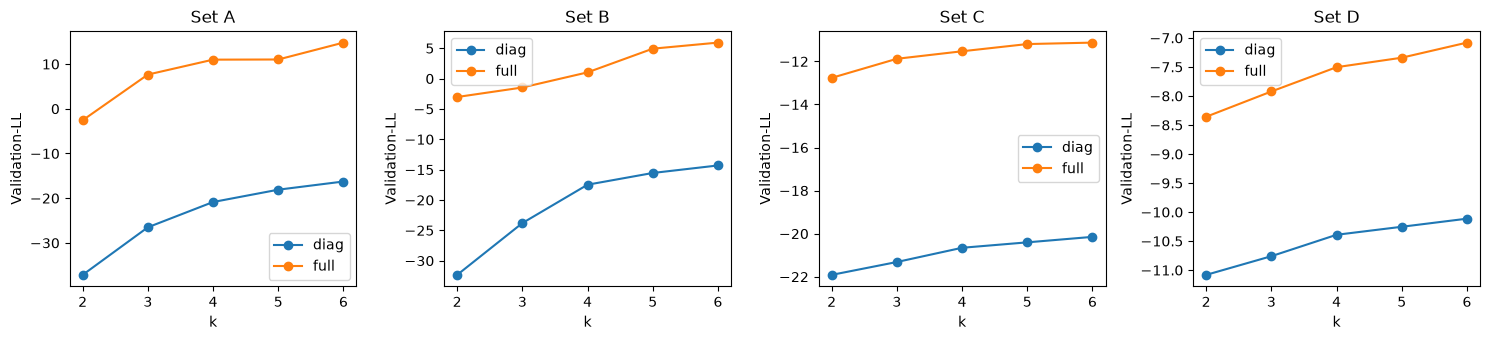

In [9]:
# problem cases where not converged or log-likelihood na
problems = cv.loc[~cv.converged | cv.valid_log_likelihood.isna()]
print("Problematic runs:", len(problems))
display(problems.head())
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, name in zip(axes, feature_sets):
    sub = cv_summary.loc[cv_summary.feature_set == name]
    for covariance, group in sub.groupby("covariance"):
        group.sort_values("k").plot(x="k", y="mean_valid_ll", ax=ax, marker="o", label=covariance)
    ax.set_title(f"Set {name}")
    ax.set_ylabel("Validation-LL")
save_figure(fig, OUT, "03_gmm_cv_within_sets.png")
plt.show()

### Interpretation from plot
Full covariance performs better in almost every comparison, but set B with k=6 has a serious failure on the 2020 validation period. Full covariance allows correlations between features within each component. Diagonal covariance restricts those correlations to 0. The orange curves suggest that modeling these relationships helps describe later observations (density fit).

Performance generally improves as the number of components increases, with smaller gains for Set C beyond five components. Six components gives the highest score within every feature set, so an extended search can assess whether larger values provide further improvement. Log-likelihood values should only be compared within the same feature set.





## Extended search for the number of GMM components
The initial search evaluated two to six components. For feature sets A, C, and D, the highest mean validation log-likelihood occurred at six components, the upper boundary of the tested range. This suggests that larger values should be evaluated before selecting the candidate configurations.

We extend the search to k = [5, 6, 7, 8, 10] for these feature sets using full covariance, which outperformed diagonal covariance in the initial search. Five and six components are included as reference configurations. We retain the same chronological folds, sampling procedure, and fitting settings to make comparisons consistent.

The extended search will show whether validation performance continues to improve, reaches a plateau, or deteriorates. We inspect individual-fold scores and convergence alongside the mean score, then shortlist configurations for confirmation with larger samples and additional random seeds.

In [10]:
#extended_feature_sets = {name: feature_sets[name] for name in ["A", "C", "D"]}
extended_feature_sets = feature_sets

extended_search_options = {
    "k": [5, 6, 7, 8, 10]
    ,"covariance": ["full"]
    ,"random_seeds": [24]
    ,"n_init": 2
    ,"max_iter": 200
    ,"train_cap": 50000
    ,"validation_cap": 50000
}

EXTENDED_OUT = OUT / "k_extension"
EXTENDED_OUT.mkdir(parents=True, exist_ok=True)

write_json(
    EXTENDED_OUT / "search_settings.json",
    {
        "options": extended_search_options,
        "random_seed": cfg.random_seed,
        "feature_sets": extended_feature_sets,
    },
)



In [11]:
extended_cv = run_gmm_cv(
    development_rows
    ,extended_feature_sets
    ,cfg
    ,search_options=extended_search_options
)

extended_cv.to_csv(
    EXTENDED_OUT / "gmm_cv.csv"
    ,index=False,
)

Starting GMM CV: 60 fits across 3 folds and 4 feature sets.

validate_2018: 349,699 training rows, 464,576 validation rows.
  Actual rows used: 50,000 training, 50,000 validation
  Preparing feature set A (42 features)...
  [1/60] validate_2018, set A, k=5, covariance=full, seed=24: done (elapsed 8.7s)
  Preparing feature set B (35 features)...
  [10/60] validate_2018, set B, k=10, covariance=full, seed=24: done (elapsed 160.7s)
  Preparing feature set C (16 features)...
  Preparing feature set D (8 features)...
  [20/60] validate_2018, set D, k=10, covariance=full, seed=24: done (elapsed 252.6s)

validate_2019: 814,275 training rows, 465,067 validation rows.
  Actual rows used: 50,000 training, 50,000 validation
  Preparing feature set A (42 features)...
  Preparing feature set B (35 features)...
  [30/60] validate_2019, set B, k=10, covariance=full, seed=24: done (elapsed 435.4s)
  Preparing feature set C (16 features)...
  Preparing feature set D (8 features)...
  [40/60] validate_2

In [12]:
shortlist = shortlist_gmm_configurations(
    cv_results=extended_cv
    ,top_n=2
)

display(shortlist)

,feature_set,k,covariance,mean_valid_ll,std_valid_ll,all_converged,n_runs,n_scored
0,A,6,full,14.800465,6.091921,True,3,3
1,A,7,full,13.735074,4.901650,True,3,3
2,B,6,full,5.931433,4.498042,True,3,3
3,B,5,full,4.931790,5.338826,True,3,3
4,C,10,full,-10.566016,2.181298,True,3,3
5,C,8,full,-10.754380,1.984846,True,3,3
6,D,10,full,-6.446124,1.103152,True,3,3
7,D,8,full,-6.722981,1.150159,True,3,3


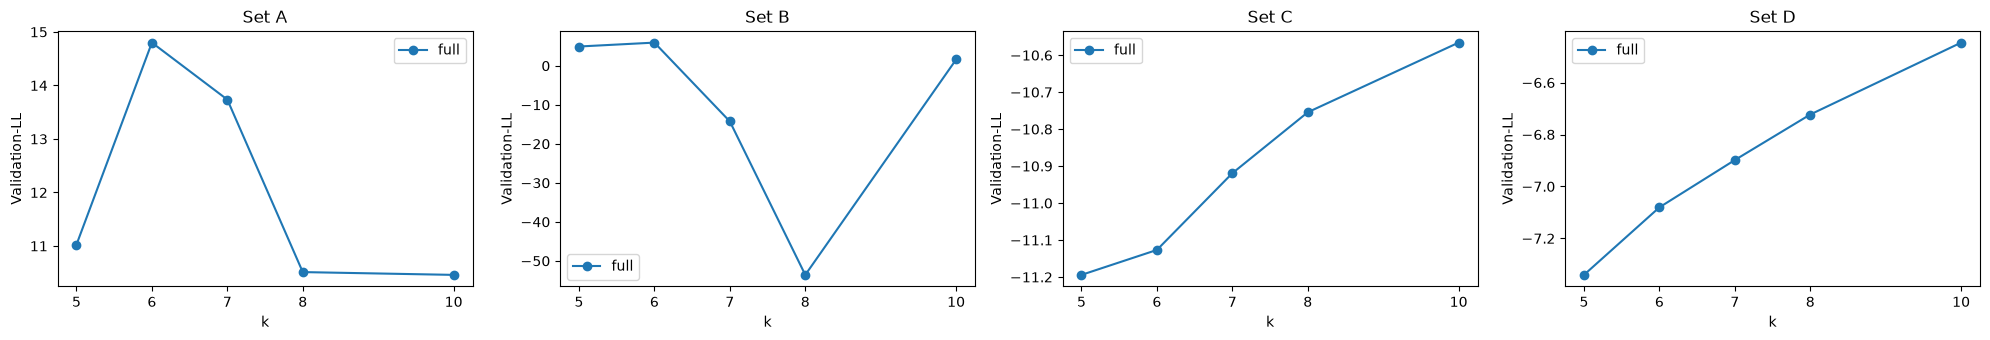

In [13]:
extended_summary = summarize_cv(extended_cv)
feature_set_names = extended_summary["feature_set"].unique()

fig, axes = plt.subplots(
    1
    ,len(feature_set_names)
    ,figsize=(5 * len(feature_set_names), 3.5)
)

for ax, name in zip(np.atleast_1d(axes), feature_set_names):
    feature_set_summary = extended_summary.loc[
        extended_summary["feature_set"].eq(name)
    ]

    for covariance, group in feature_set_summary.groupby("covariance"):
        group.sort_values("k").plot(
            x="k"
            ,y="mean_valid_ll"
            ,ax=ax
            ,marker="o"
            ,label=covariance
        )

    ax.set_title(f"Set {name}")
    ax.set_xlabel("k")
    ax.set_ylabel("Validation-LL")
    ax.set_xticks(sorted(feature_set_summary["k"].unique()))

(EXTENDED_OUT / "figures").mkdir(
    parents=True
    ,exist_ok=True
)

save_figure(
    fig
    ,EXTENDED_OUT
    ,"03_gmm_extended_cv_within_sets.png"
)

plt.show()

## Extended search: the feature sets behave differently
For A, the extension identifies a peak at 6 components, then declines so additional components do not improve the average screening LL. For C and D, 10 is the best component. Set B shows irregular validation performance, with sharp mean-score reductions caused by different validation years at different component counts.

The feature sets describe different aspects of the observations. A (42 features) is a broad description of market behaviour, company finances, and events with all usable features. B (35 features) is A after removing features with very high pairwise Spearman correlation in the 2017 selection period (> 0.95). C (16 features) is B’s market-behaviour features, excluding financial and event features. D (4 features) have momentum, volatility, and relative-volume features. So D is contained within C, C within B, and B within A.

In [14]:
confirmation_options = {
    "train_cap": 200000
    ,"validation_cap": None       # Score the complete validation year
    ,"random_seeds": [4, 14, 24]  # 3 GMM initialization seeds
    ,"n_init": 2
    ,"max_iter": 300
}

In [15]:
confirmation_dir = OUT / "confirmation"
confirmation_dir.mkdir(parents=True, exist_ok=True)

shortlist.to_csv(confirmation_dir / "shortlist.csv",index=False)

write_json(
    confirmation_dir / "settings.json"
    ,{
        "options": confirmation_options
        ,"sampling_seed": cfg.random_seed
        ,"shortlist": shortlist[["feature_set", "k", "covariance"]].to_dict(orient="records")
    }
)

confirmation_batches = []

for (feature_set_name, covariance_type), config in (
    shortlist.groupby(["feature_set", "covariance"], sort=False)
):
    component_counts = sorted(config["k"].astype(int).unique().tolist())

    current_search_options = {
        **confirmation_options
        ,"k": component_counts
        ,"covariance": [covariance_type]
    }

    print(
        f"\nConfirming set {feature_set_name}: "
        ,f"k={component_counts}, covariance={covariance_type}"
        ,flush=True
    )

    batch_results = run_gmm_cv(
        rows=development_rows,
        feature_sets={
            feature_set_name: feature_sets[feature_set_name]
        },
        cfg=cfg,
        search_options=current_search_options,
    )

    confirmation_batches.append(batch_results)


    confirmation_cv = pd.concat(
        confirmation_batches,
        ignore_index=True,
    )

    confirmation_cv.to_csv(
        confirmation_dir / "gmm_cv.csv",
        index=False,
    )


Confirming set A:  k=[6, 7], covariance=full
Starting GMM CV: 18 fits across 3 folds and 1 feature sets.

validate_2018: 349,699 training rows, 464,576 validation rows.
  Actual rows used: 200,000 training, 464,576 validation
  Preparing feature set A (42 features)...
  [1/18] validate_2018, set A, k=6, covariance=full, seed=4: done (elapsed 40.5s)

validate_2019: 814,275 training rows, 465,067 validation rows.
  Actual rows used: 200,000 training, 465,067 validation
  Preparing feature set A (42 features)...
  [10/18] validate_2019, set A, k=7, covariance=full, seed=4: done (elapsed 486.7s)

validate_2020: 1,279,342 training rows, 475,518 validation rows.
  Actual rows used: 200,000 training, 475,518 validation
  Preparing feature set A (42 features)...
  [18/18] validate_2020, set A, k=7, covariance=full, seed=24: done (elapsed 889.9s)
GMM CV complete: 18/18 fits in 889.9s.

Confirming set B:  k=[5, 6], covariance=full
Starting GMM CV: 18 fits across 3 folds and 1 feature sets.

val

In [16]:
confirmation_summary = summarize_cv(confirmation_cv)

first_validation_year = (pd.Timestamp(cfg.feature_selection_end).year + 1)

number_of_folds = (pd.Timestamp(cfg.development_end).year
    - first_validation_year
    + 1)

expected_runs_per_configuration = (
    number_of_folds
    * len(confirmation_options["random_seeds"])
)

eligible_confirmation = confirmation_summary.loc[
    confirmation_summary["all_converged"]
    & confirmation_summary["n_runs"].eq(
        expected_runs_per_configuration
    )
    & confirmation_summary["n_scored"].eq(
        expected_runs_per_configuration
    )
].copy()

confirmation_summary.to_csv(
    confirmation_dir / "summary.csv",
    index=False,
)

display(confirmation_summary)

,feature_set,k,covariance,mean_valid_ll,std_valid_ll,all_converged,n_runs,n_scored
0,A,6,full,13.478275,7.669552,True,9,9
1,A,7,full,10.150582,10.502822,True,9,9
3,B,6,full,-39.893309,55.758735,True,9,9
2,B,5,full,-43.393900,53.104653,True,9,9
5,C,10,full,-10.616929,1.733508,True,9,9
4,C,8,full,-10.884612,1.718830,True,9,9
7,D,10,full,-6.517005,0.933779,True,9,9
6,D,8,full,-6.801458,0.941382,True,9,9


In [17]:
scores_by_year = (
    confirmation_cv
    .groupby(
        ["feature_set", "k", "covariance", "fold"]
    )["valid_log_likelihood"]
    .mean()  # Average over seeds within each year/fold
    .unstack("fold")
)

display(scores_by_year)

fold                       validate_2018  validate_2019  validate_2020
feature_set k  covariance                                             
A           6  full            17.917400      18.650732       3.866694
            7  full            18.571105       6.374606       5.506035
B           5  full          -112.796296     -15.627504      -1.757900
            6  full          -112.528955      -1.099705      -6.051268
C           8  full           -11.348481      -8.711347     -12.594009
            10 full           -11.099882      -8.419247     -12.331658
D           8  full            -7.000723      -5.629729      -7.773922
            10 full            -6.713081      -5.354359      -7.483574

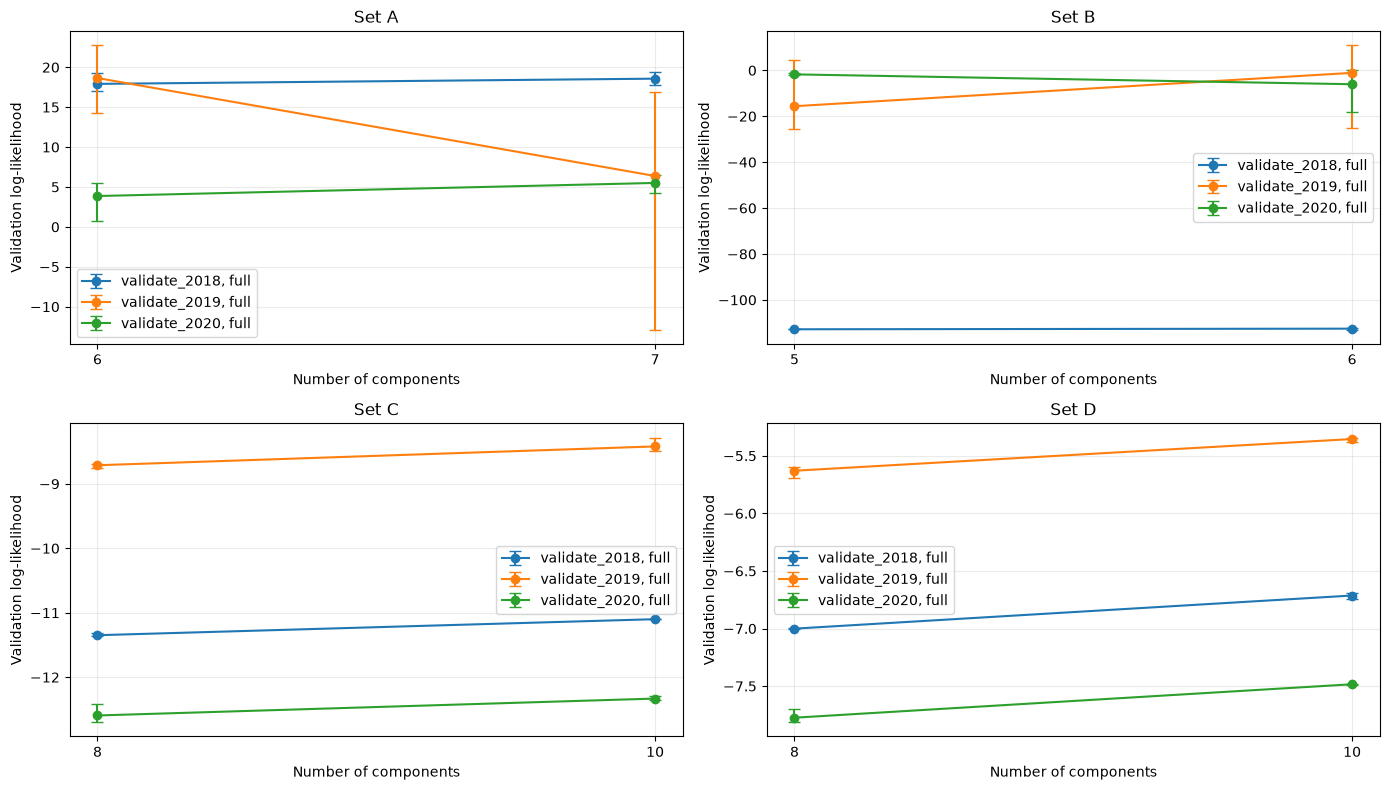

In [18]:

confirmation_plot_summary = (
    confirmation_cv
    .groupby(
        ["feature_set", "k", "covariance", "fold"]
        ,as_index=False
    )
    .agg(
        mean_valid_ll=("valid_log_likelihood", "mean")
        ,minimum_valid_ll=("valid_log_likelihood", "min")
        ,maximum_valid_ll=("valid_log_likelihood", "max")
    )
)

feature_set_names = sorted(
    confirmation_plot_summary["feature_set"].unique()
)

number_of_columns = min(2, len(feature_set_names))
number_of_rows = int(
    np.ceil(len(feature_set_names) / number_of_columns)
)

fig, axes = plt.subplots(
    number_of_rows
    ,number_of_columns
    ,figsize=(7 * number_of_columns, 4 * number_of_rows)
    ,squeeze=False
)

for ax, feature_set_name in zip(
    axes.ravel()
    ,feature_set_names
):
    feature_set_results = confirmation_plot_summary.loc[
        confirmation_plot_summary["feature_set"].eq(feature_set_name)
    ]

    for (fold_name, covariance_type), group in (feature_set_results.groupby(["fold", "covariance"])):
        group = group.sort_values("k")

        seed_score_ranges = np.vstack([
            group["mean_valid_ll"] - group["minimum_valid_ll"]
            ,group["maximum_valid_ll"] - group["mean_valid_ll"]
        ])

        ax.errorbar(
            group["k"]
            ,group["mean_valid_ll"]
            ,yerr=seed_score_ranges
            ,fmt="o-"
            ,capsize=4
            ,label=f"{fold_name}, {covariance_type}"
        )

    ax.set_title(f"Set {feature_set_name}")
    ax.set_xlabel("Number of components")
    ax.set_ylabel("Validation log-likelihood")
    ax.set_xticks(sorted(feature_set_results["k"].unique()))
    ax.grid(
        True
        ,alpha=0.25
    )
    ax.legend()

# Hide panels that are not needed.
for ax in axes.ravel()[len(feature_set_names):]:
    ax.set_visible(False)

confirmation_directory = OUT / "confirmation"

(confirmation_directory / "figures").mkdir(
    parents=True
    ,exist_ok=True
)

save_figure(
    fig
    ,confirmation_directory
    ,"04_confirmation_by_year_and_seed.png"
)

plt.show()

Set A prefers 6 components. 7 components slightly improves the year-average score in 2018 and 2020, but performs much worse in 2019. The poor initialization in 2019 with 3 seeds explains the large orange error bar. Six components has a higher overall mean and avoids this particular failure, although its scores also vary between years and seeds.

For set B, both configurations score approximately −113 in 2018, consistently across seeds. The failure affects both five and six components and repeating initialization does not resolve the 2018 problem. In 2019 and 2020, some configurations also vary substantially between seeds. 6 has the better average, but that is insufficient evidence to accept it as reliable.

For set C, 10 consistently improves on 8. Small error bars indicate limited initialization sensitivity under this particular training sample. The larger differences between years indicate that temporal variation remains important.

For set D, 10 also provides a consistent improvement. 


## Inspect overtraining

In [20]:

def count_gmm_parameters(result_row):
    """Count means, covariance parameters and independent mixture weights."""
    number_of_components = int(result_row["k"])
    number_of_features = int(result_row["n_features"])

    mean_parameters = (
        number_of_components * number_of_features
    )

    weight_parameters = number_of_components - 1

    if result_row["covariance"] == "full":
        covariance_parameters = (
            number_of_components
            * number_of_features
            * (number_of_features + 1)
            // 2
        )
    elif result_row["covariance"] == "diag":
        covariance_parameters = (
            number_of_components * number_of_features
        )
    else:
        raise ValueError("This diagnostic supports full and diag covariance.")

    return (
        mean_parameters
        + covariance_parameters
        + weight_parameters
    )


In [21]:
cv_stage_paths = {
    "Original": OUT / "gmm_cv.csv"
    ,"Extended": OUT / "k_extension" / "gmm_cv.csv"
    ,"Confirmation": OUT / "confirmation" / "gmm_cv.csv"
}

diagnostic_directory = OUT / "overfitting_diagnostics"
diagnostic_directory.mkdir(
    parents=True
    ,exist_ok=True
)


stage_results = []

for stage_name, results_path in cv_stage_paths.items():
    results = pd.read_csv(results_path)

    results["stage"] = stage_name

    results["converged"] = (
        results["converged"]
        .astype(str)
        .str.lower()
        .eq("true")
    )

    results["number_of_parameters"] = results.apply(
        count_gmm_parameters
        ,axis=1
    )

    results["train_log_likelihood"] = (
        results["number_of_parameters"] * np.log(results["n_train"])
        - results["train_bic"]
    ) / (2 * results["n_train"])

    results["generalization_gap"] = (
        results["train_log_likelihood"]
        - results["valid_log_likelihood"]
    )

    stage_results.append(results)

diagnostic_runs = pd.concat(
    stage_results
    ,ignore_index=True
)

diagnostic_runs.to_csv(
    diagnostic_directory / "diagnostic_runs.csv"
    ,index=False
)

In [22]:
diagnostic_runs["usable_score"] = (
    np.isfinite(diagnostic_runs["train_log_likelihood"])
    & np.isfinite(diagnostic_runs["valid_log_likelihood"])
)

problematic_runs = diagnostic_runs.loc[
    ~diagnostic_runs["converged"]
    | ~diagnostic_runs["usable_score"]
]

print("Non-converged or unscored runs:", len(problematic_runs))

display(
    problematic_runs[
        [
            "stage"
            ,"feature_set"
            ,"fold"
            ,"k"
            ,"covariance"
            ,"seed"
            ,"converged"
            ,"error"
        ]
    ]
)

Non-converged or unscored runs: 0


,stage,feature_set,fold,k,covariance,seed,converged,error


In [23]:
scored_runs = diagnostic_runs.loc[diagnostic_runs["usable_score"]].copy()

diagnostic_summary = (
    scored_runs
    .groupby(
        ["stage", "feature_set", "covariance", "k"]
        ,as_index=False
    )
    .agg(
        mean_train_ll=("train_log_likelihood", "mean")
        ,mean_valid_ll=("valid_log_likelihood", "mean")
        ,mean_gap=("generalization_gap", "mean")
        ,worst_valid_ll=("valid_log_likelihood", "min")
        ,all_converged=("converged", "all")
        ,n_runs=("seed", "size")
    )
    .sort_values(
        ["stage", "feature_set", "covariance", "k"]
    )
)

display(diagnostic_summary)

diagnostic_summary.to_csv(
    diagnostic_directory / "diagnostic_summary.csv"
    ,index=False
)

,stage,feature_set,covariance,k,mean_train_ll,mean_valid_ll,mean_gap,worst_valid_ll,all_converged,n_runs
0,Confirmation,A,full,6,23.393650,13.478275,9.915374,0.701842,True,9
1,Confirmation,A,full,7,24.359717,10.150582,14.209135,-12.892280,True,9
2,Confirmation,B,full,5,9.645875,-43.393900,53.039775,-112.796320,True,9
3,Confirmation,B,full,6,10.623919,-39.893309,50.517229,-113.011567,True,9
4,Confirmation,C,full,8,-8.049647,-10.884612,2.834966,-12.699322,True,9
...,...,...,...,...,...,...,...,...,...,...
63,Original,D,full,2,-7.018787,-8.357997,1.339210,-9.404460,True,3
64,Original,D,full,3,-6.610583,-7.922468,1.311885,-8.971224,True,3
65,Original,D,full,4,-6.193991,-7.503832,1.309840,-8.527359,True,3
66,Original,D,full,5,-5.970117,-7.340577,1.370460,-8.349765,True,3


In [29]:
diagnostic_summary.loc[diagnostic_summary["stage"] == "Extended"]

,stage,feature_set,covariance,k,mean_train_ll,mean_valid_ll,mean_gap,worst_valid_ll,all_converged,n_runs
8,Extended,A,full,5,21.997467,11.024320,10.973147,4.082210,True,3
9,Extended,A,full,6,23.176657,14.800465,8.376192,7.838673,True,3
10,Extended,A,full,7,24.818208,13.735074,11.083134,8.650619,True,3
11,Extended,A,full,8,25.516491,10.511719,15.004772,5.900642,True,3
12,Extended,A,full,10,27.193283,10.459497,16.733786,-0.900998,True,3
13,Extended,B,full,5,10.090862,4.931790,5.159071,-0.563546,True,3
14,Extended,B,full,6,11.147056,5.931433,5.215623,1.163309,True,3
15,Extended,B,full,7,11.743729,-14.261148,26.004877,-61.269910,True,3
16,Extended,B,full,8,12.561217,-53.587608,66.148825,-170.479844,True,3
17,Extended,B,full,10,13.514553,1.604457,11.910096,-9.968118,True,3


In [30]:
diagnostic_summary.loc[diagnostic_summary["stage"] == "Confirmation"]

,stage,feature_set,covariance,k,mean_train_ll,mean_valid_ll,mean_gap,worst_valid_ll,all_converged,n_runs
0,Confirmation,A,full,6,23.393650,13.478275,9.915374,0.701842,True,9
1,Confirmation,A,full,7,24.359717,10.150582,14.209135,-12.892280,True,9
2,Confirmation,B,full,5,9.645875,-43.393900,53.039775,-112.796320,True,9
3,Confirmation,B,full,6,10.623919,-39.893309,50.517229,-113.011567,True,9
4,Confirmation,C,full,8,-8.049647,-10.884612,2.834966,-12.699322,True,9
5,Confirmation,C,full,10,-7.742356,-10.616929,2.874572,-12.354208,True,9
6,Confirmation,D,full,8,-5.406106,-6.801458,1.395353,-7.813613,True,9
7,Confirmation,D,full,10,-5.135293,-6.517005,1.381711,-7.486527,True,9


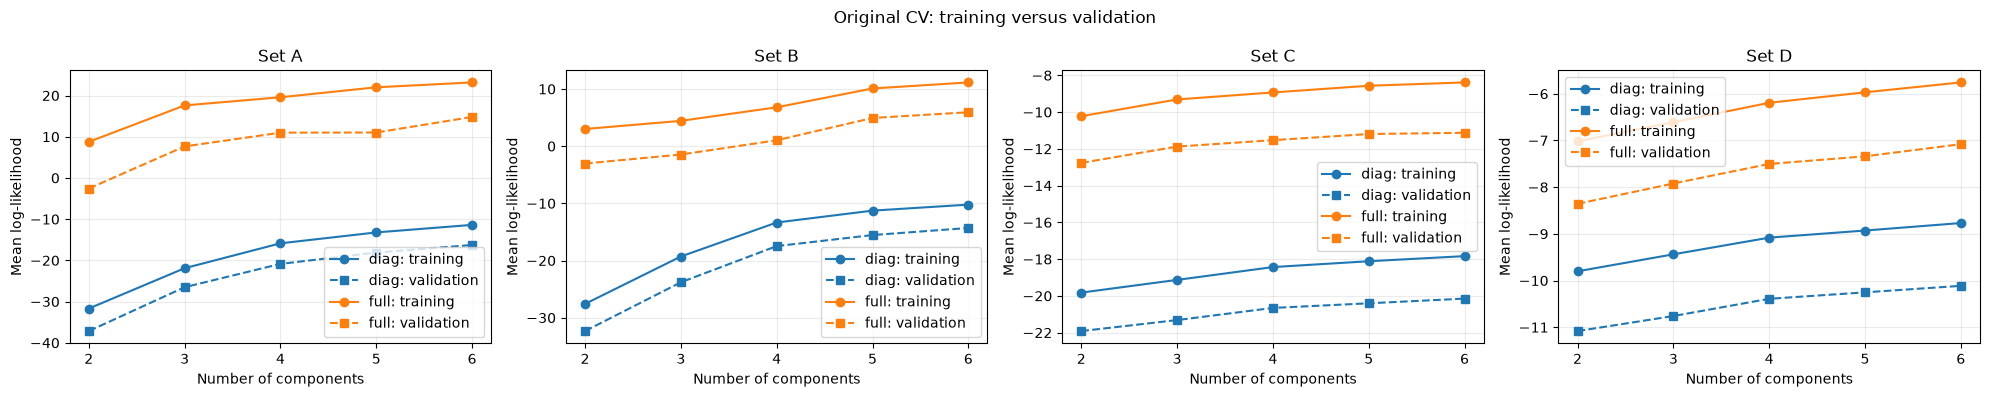

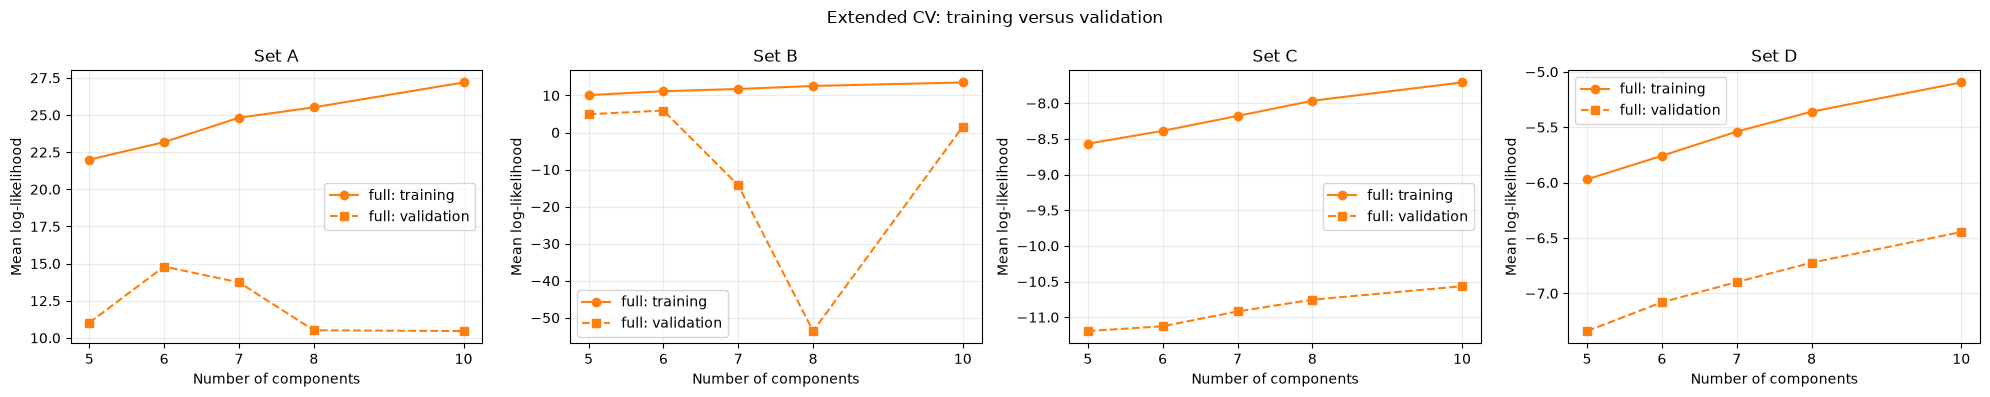

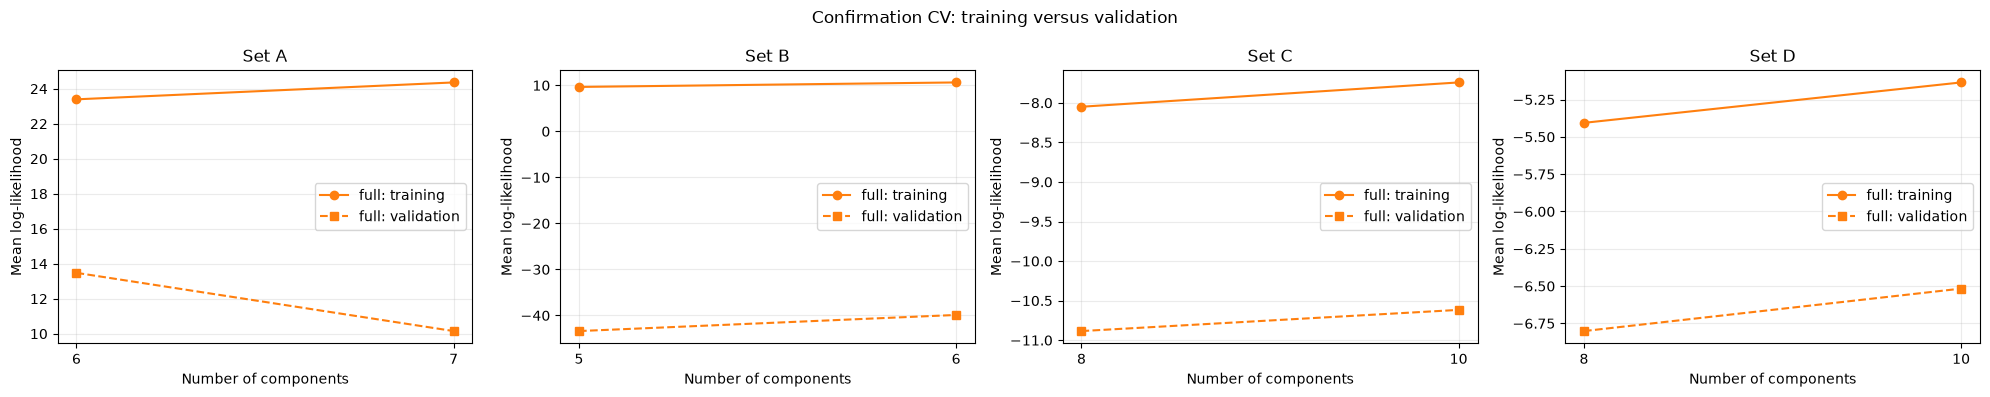

In [24]:
covariance_colors = {
    "diag": "tab:blue"
    ,"full": "tab:orange"
}

for stage_name in cv_stage_paths:
    stage_summary = diagnostic_summary.loc[
        diagnostic_summary["stage"].eq(stage_name)
    ]

    feature_set_names = sorted(
        stage_summary["feature_set"].unique()
    )

    if not feature_set_names:
        continue

    fig, axes = plt.subplots(
        1
        ,len(feature_set_names)
        ,figsize=(5 * len(feature_set_names), 4)
        ,squeeze=False
    )

    for ax, feature_set_name in zip(
        axes.ravel()
        ,feature_set_names
    ):
        feature_summary = stage_summary.loc[
            stage_summary["feature_set"].eq(feature_set_name)
        ]

        for covariance_type, group in feature_summary.groupby("covariance"):
            group = group.sort_values("k")
            color = covariance_colors[covariance_type]

            ax.plot(
                group["k"]
                ,group["mean_train_ll"]
                ,color=color
                ,marker="o"
                ,linestyle="-"
                ,label=f"{covariance_type}: training"
            )

            ax.plot(
                group["k"]
                ,group["mean_valid_ll"]
                ,color=color
                ,marker="s"
                ,linestyle="--"
                ,label=f"{covariance_type}: validation"
            )

        ax.set_title(f"Set {feature_set_name}")
        ax.set_xlabel("Number of components")
        ax.set_ylabel("Mean log-likelihood")
        ax.set_xticks(sorted(feature_summary["k"].unique()))
        ax.grid(
            True
            ,alpha=0.25
        )
        ax.legend()

    fig.suptitle(f"{stage_name} CV: training versus validation")
    fig.tight_layout()

    fig.savefig(
        diagnostic_directory / f"{stage_name.lower()}_overfitting.png"
        ,dpi=150
        ,bbox_inches="tight"
    )

    plt.show()

#### Original CV 
The figure has no clear overall deterioration up to 6 components. For all four feature sets, training and average validation likelihood generally improve as k increases. Full covariance also performs better on validation than diagonal covariance. Within this range, there is no clear overall turning point where added complexity consistently harms validation performance. Training scores are higher than validation scores, but that gap alone does not establish overfitting. Training and validation cover different years, so distribution changes can contribute.

#### Extended CV 
The figures show that A and B have different problems. Set A shows a clear complexity-related warning. From 6 to 10 components, meaning training LL increases from 23.18 to 27.19 while mean validation LL increases 14.80 to 10.46. The model increasingly fits the training distribution while becoming less effective on later observations. This is strong evidence consistent with overfitting beyond six components under the tested conditions.

Set B shows irregular, sometimes catastrophic generalization failures. Its training curve improves smoothly, while validation collapses at 7 and 8 components and partially recovers at 10. Narrow covariance estimates, initialization sensitivity, unusual validation observations, or changing feature relationships could contribute.

C and D improve on both training and validation. Their curves remain roughly parallel. There is no clear overfitting turning point through ten components, although ten remains the upper tested boundary.

#### Confirmation 
It strengthens some conclusions and changes others. 

For A, training improves from 6 to 7 while validation falls. Table shows that seven performs worse in the 2019 fold for all three seeds, with a decreases in validation. Thus, the concern is not solely one unfortunate initialization, although one seed makes it much worse.

For B, 6 improves the mean, but both configurations have severe failures. This is an unresolved generalization problem already present at 5 components.

For C and D, the confirmation gains from 8 to 10 are approximately 0.268 and 0.284, respectively. These improvements occur across all tested year/seed pairs, making them more credible than an improvement driven by one favorable run. They still do not prove that 10 interpretable market states exist.



In [25]:
comparison_keys = [
    "stage"
    ,"feature_set"
    ,"covariance"
    ,"fold"
    ,"seed"
    ,"n_train"
    ,"n_valid"
    ,"n_features"
]

if scored_runs.duplicated(comparison_keys + ["k"]).any():
    raise ValueError("Duplicate CV runs found. Check the input tables.")

paired_comparisons = scored_runs.sort_values(
    comparison_keys + ["k"]
).copy()

matched_groups = paired_comparisons.groupby(comparison_keys)

paired_comparisons["previous_k"] = matched_groups["k"].shift()

paired_comparisons["training_change"] = (
    matched_groups["train_log_likelihood"].diff()
)

paired_comparisons["validation_change"] = (
    matched_groups["valid_log_likelihood"].diff()
)

previous_converged = matched_groups["converged"].shift(
    fill_value=False
)

paired_comparisons["overfitting_warning"] = (
    paired_comparisons["converged"]
    & previous_converged
    & paired_comparisons["training_change"].gt(0.000001)
    & paired_comparisons["validation_change"].lt(-0.000001)
)

warning_runs = paired_comparisons.loc[
    paired_comparisons["overfitting_warning"]
].sort_values("validation_change")

display(
    warning_runs[
        [
            "stage"
            ,"feature_set"
            ,"fold"
            ,"covariance"
            ,"seed"
            ,"previous_k"
            ,"k"
            ,"training_change"
            ,"validation_change"
        ]
    ]
)

warning_runs.to_csv(
    diagnostic_directory / "overfitting_warnings.csv"
    ,index=False
)

,stage,feature_set,fold,covariance,seed,previous_k,k,training_change,validation_change
148,Extended,B,validate_2019,full,24,7.0,8,0.579630,-181.410727
167,Extended,B,validate_2020,full,24,6.0,7,0.384125,-62.433219
191,Confirmation,A,validate_2019,full,24,6.0,7,2.105903,-27.180964
124,Extended,A,validate_2018,full,24,8.0,10,1.901939,-19.499847
129,Extended,B,validate_2018,full,24,8.0,10,0.726206,-17.779649
215,Confirmation,B,validate_2020,full,24,5.0,6,0.708569,-16.295698
143,Extended,A,validate_2019,full,24,7.0,8,1.372135,-7.088171
189,Confirmation,A,validate_2019,full,4,6.0,7,0.376298,-5.908463
142,Extended,A,validate_2019,full,24,6.0,7,2.791195,-5.030215
47,Original,A,validate_2019,full,24,4.0,5,3.090884,-4.507997
